# Tarea 1 · Parte 1: de El Comercio a un CSV limpio

Pregunta guía: **¿se pueden convertir titulares peruanos en un clasificador de noticias?**
Antes de clasificar nada hay que tener datos en los que se pueda confiar. Este notebook cubre
recolección, limpieza y una primera mirada exploratoria. Elegí la **opción B (El Comercio)**.

Decisiones de diseño, para que se pueda discutir cada una:

- **Fuente.** `robots.txt` de El Comercio no prohíbe las páginas de artículos (solo `/catalogo/`, `/buscar/`
  y `/archivo/…`) y publica sitemaps por sección. Parto de ahí en vez de rastrear el HTML de portada,
  que cambia más seguido.
- **Cortesía.** User-Agent que dice quién soy, 1.5 s entre pedidos, máximo 1 reintento.
- **Reanudable.** Cada artículo descargado se guarda en `datos/raw/`. Si el notebook se cae a la mitad,
  al volver a correrlo no repite lo ya descargado.
- **Etiqueta provisional.** En esta parte la etiqueta sale de la sección del sitemap de donde vino la URL.
  Es una etiqueta barata y con ruido: en la Parte 2 la contrasto con un LLM y reviso los desacuerdos.

In [1]:
import json
import re
import time
import urllib.robotparser
from collections import Counter
from pathlib import Path
from urllib.parse import urlparse

import matplotlib.pyplot as plt
import pandas as pd
import requests
import seaborn as sns
from bs4 import BeautifulSoup

sns.set_theme(style="whitegrid", context="notebook")

RAW = Path("datos/raw")
RAW.mkdir(parents=True, exist_ok=True)

HEADERS = {"User-Agent": "tarea1-ds-python-up/1.0 (trabajo academico, Universidad del Pacifico; fampuero@poverty-action.org)"}
PAUSA = 1.5          # segundos entre pedidos
BASE = "https://elcomercio.pe"

## 1. ¿Me dejan entrar?

En vez de confiar en mi lectura del `robots.txt`, se lo pregunto a `urllib.robotparser` con mi propio User-Agent
y con las rutas que voy a pedir.

In [2]:
rp = urllib.robotparser.RobotFileParser(f"{BASE}/robots.txt")
rp.set_url(f"{BASE}/robots.txt")
rp.read()

pruebas = [
    "/sitemap/web/politica/?outputType=xml",
    "/politica/gobierno/un-articulo-cualquiera-noticia/",
    "/deporte-total/futbol-peruano/otro-articulo-noticia/",
    "/buscar/?query=congreso",
]
for ruta in pruebas:
    print(f"{'permitido' if rp.can_fetch(HEADERS['User-Agent'], BASE + ruta) else 'BLOQUEADO':<10} {ruta}")

permitido  /sitemap/web/politica/?outputType=xml
permitido  /politica/gobierno/un-articulo-cualquiera-noticia/
permitido  /deporte-total/futbol-peruano/otro-articulo-noticia/
BLOQUEADO  /buscar/?query=congreso


Las rutas de artículos y sitemaps quedan permitidas; `/buscar/` no, y por eso no la uso.

## 2. Candidatas desde los sitemaps

Cada sección tiene un sitemap con las 100 URLs más recientes. Con cuatro secciones salen 400 candidatas, justo
el volumen que pide la tarea (350–400), antes de descartar lo que no sirva.

In [3]:
SECCIONES = {                      # etiqueta oficial -> sección del sitemap
    "politica": "politica",
    "economia": "economia",
    "deportes": "deporte-total",
    "ciencia_tecnologia": "tecnologia",
}

def pedir(url, reintentos=1):
    """GET cortés: pausa fija y como máximo un reintento."""
    for intento in range(reintentos + 1):
        time.sleep(PAUSA)
        try:
            r = requests.get(url, headers=HEADERS, timeout=30)
            if r.status_code == 200:
                return r
            print(f"  HTTP {r.status_code} en {url}")
        except requests.RequestException as e:
            print(f"  error de red ({type(e).__name__}) en {url}")
    return None

candidatas = []
for etiqueta, seccion in SECCIONES.items():
    r = pedir(f"{BASE}/sitemap/web/{seccion}/?outputType=xml")
    sopa = BeautifulSoup(r.text, "xml")
    for u in sopa.find_all("url"):
        candidatas.append({"url": u.loc.text.strip(), "lastmod": u.lastmod.text.strip(),
                           "etiqueta_sitemap": etiqueta})

cand = pd.DataFrame(candidatas)
print(cand.shape)
cand.etiqueta_sitemap.value_counts()

(400, 3)


etiqueta_sitemap
politica              100
economia              100
deportes              100
ciencia_tecnologia    100
Name: count, dtype: int64

## 3. Descarga de los artículos

De cada página saco tres cosas de los metadatos Open Graph, que son más estables que las clases CSS del diseño:
`og:title` (titular), `og:description` (bajada) y `article:published_time` (fecha). Guardo todo en
`datos/raw/elcomercio_raw.json` a medida que avanzo.

In [4]:
RAW_JSON = RAW / "elcomercio_raw.json"
cache = {r["url"]: r for r in json.loads(RAW_JSON.read_text(encoding="utf-8")) if "tipo_og" in r} if RAW_JSON.exists() else {}

def meta(sopa, clave):
    tag = sopa.find("meta", attrs={"property": clave}) or sopa.find("meta", attrs={"name": clave})
    return tag["content"].strip() if tag and tag.get("content") else ""

def extraer(url, html):
    sopa = BeautifulSoup(html, "lxml")
    h1 = sopa.find("h1")
    return {
        "url": url,
        "titular": meta(sopa, "og:title") or (h1.get_text(strip=True) if h1 else ""),
        "bajada": meta(sopa, "og:description"),
        "fecha": meta(sopa, "article:published_time")[:10],
        "tipo_og": meta(sopa, "og:type"),
    }

pendientes = [u for u in cand.url if u not in cache]
print(f"{len(cache)} ya en caché, {len(pendientes)} por descargar (~{len(pendientes) * PAUSA / 60:.0f} min)")

fallos = []
for i, url in enumerate(pendientes, 1):
    r = pedir(url)
    if r is None:
        fallos.append(url)
        continue
    cache[url] = extraer(url, r.text)
    if i % 25 == 0:
        RAW_JSON.write_text(json.dumps(list(cache.values()), ensure_ascii=False, indent=1), encoding="utf-8")
        print(f"  {i}/{len(pendientes)}")

RAW_JSON.write_text(json.dumps(list(cache.values()), ensure_ascii=False, indent=1), encoding="utf-8")
print(f"Descargadas: {len(cache)} · fallos tras reintento: {len(fallos)}")

399 ya en caché, 0 por descargar (~0 min)


Descargadas: 399 · fallos tras reintento: 0


## 4. Limpieza y descartes

Reglas, todas explícitas y todas reportadas (la tarea pide no esconder lo que se descarta):

1. Sin titular o sin bajada utilizable (menos de 30 caracteres) → se descarta.
2. URL repetida entre sitemaps → se queda una.
3. **La URL debe empezar por la sección esperada.** Los sitemaps de El Comercio arrastran notas de otras
   secciones (opinión, `ecdata`, `ruedas-tuercas`, BBC Mundo…). Si una nota de `tecnologia` vive en
   `/ruedas-tuercas/`, no es claramente ciencia y tecnología: no invento una quinta categoría, la descarto.

In [5]:
df = cand.merge(pd.DataFrame(cache.values()), on="url", how="left")
df["segmento"] = df.url.map(lambda u: urlparse(u).path.strip("/").split("/")[0])
df["subseccion"] = df.url.map(lambda u: (lambda seg: seg[1] if len(seg) >= 3 else "")(urlparse(u).path.strip("/").split("/")))

esperado = {et: sec for et, sec in SECCIONES.items()}
descartes = []

def descartar(mask, motivo):
    global df
    for _, f in df[mask].iterrows():
        descartes.append({"url": f.url, "etiqueta_sitemap": f.etiqueta_sitemap,
                          "seccion_url": f.segmento, "motivo": motivo})
    df = df[~mask]

descartar(df.titular.isna() | (df.titular.fillna("").str.len() == 0), "sin titular (no se pudo descargar)")
descartar(df.bajada.fillna("").str.len() < 30, "bajada ausente o demasiado corta")
descartar(df.url.duplicated(keep="first"), "URL repetida entre sitemaps")
descartar(df.titular.duplicated(keep="first"), "titular repetido")
descartar(df.segmento != df.etiqueta_sitemap.map(esperado), "la nota vive en otra sección del diario")

desc = pd.DataFrame(descartes)
(RAW / "descartes.json").write_text(desc.to_json(orient="records", force_ascii=False, indent=1), encoding="utf-8")
print(f"Quedan {len(df)} de {len(cand)}. Descartadas: {len(desc)}")
display(desc.groupby(["motivo", "seccion_url"]).size().rename("n").reset_index())

Quedan 382 de 400. Descartadas: 18


,motivo,seccion_url,n
0,URL repetida entre sitemaps,tecnologia,1
1,bajada ausente o demasiado corta,ecdata,1
2,la nota vive en otra sección del diario,bbc-news-mundo,2
3,la nota vive en otra sección del diario,ecdata,3
4,la nota vive en otra sección del diario,eldominical,1
5,la nota vive en otra sección del diario,elecciones,1
6,la nota vive en otra sección del diario,opinion,6
7,la nota vive en otra sección del diario,ruedas-tuercas,2
8,la nota vive en otra sección del diario,tecnologia,1


## 5. Esquema final y control de calidad

`seccion_original` es la subsección tal como aparece en la URL del diario (`futbol-peruano`, `inteligencia-artificial`…).

In [6]:
final = pd.DataFrame({
    "titular": df.titular.str.strip(),
    "bajada": df.bajada.str.strip(),
    "medio": "El Comercio",
    "seccion_original": df.subseccion.where(df.subseccion != "", df.segmento),
    "url": df.url,
    "fecha": df.fecha,
    "etiqueta": df.etiqueta_sitemap,
}).reset_index(drop=True)

assert final.shape[1] == 7 and final.url.is_unique
assert set(final.etiqueta) == set(SECCIONES), "faltan categorías"
assert final.isna().sum().sum() == 0

final.to_csv("datos/noticias.csv", index=False, encoding="utf-8")
print(final.shape)
final.etiqueta.value_counts()

(382, 7)


etiqueta
economia              99
deportes              98
ciencia_tecnologia    94
politica              91
Name: count, dtype: int64

### ¿Las URLs siguen vivas?

La tarea exige enlaces funcionales. Compruebo una muestra de 30 con `HEAD` (más liviano que `GET`).

In [7]:
muestra = final.sample(30, random_state=0)
estados = []
for u in muestra.url:
    time.sleep(PAUSA)
    try:
        estados.append(requests.head(u, headers=HEADERS, timeout=30, allow_redirects=True).status_code)
    except requests.RequestException:
        estados.append(None)
print(Counter(estados))

Counter({200: 30})


## 6. Primera mirada a los datos

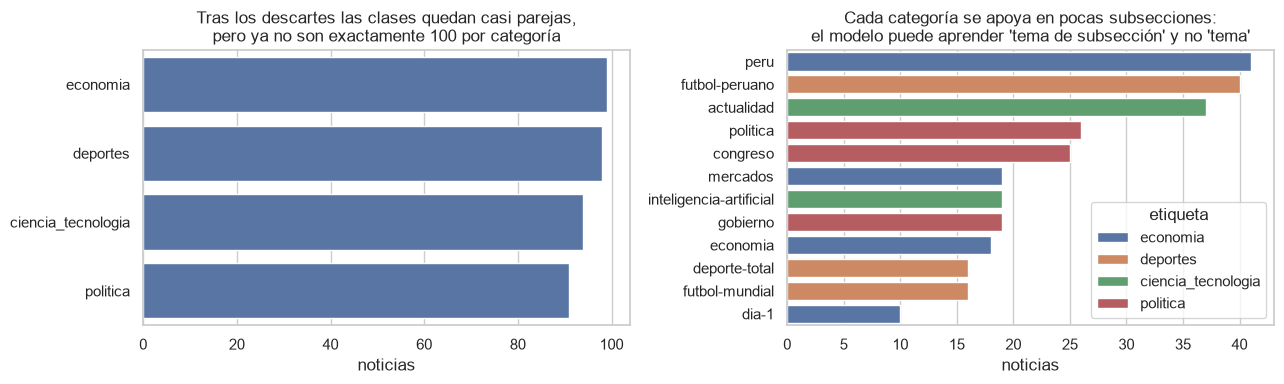

In [8]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4))

orden = final.etiqueta.value_counts().index
sns.countplot(data=final, y="etiqueta", order=orden, color="#4C72B0", ax=ejes[0])
ejes[0].set_title("Tras los descartes las clases quedan casi parejas,\npero ya no son exactamente 100 por categoría")
ejes[0].set_xlabel("noticias"); ejes[0].set_ylabel("")

sub = final.groupby(["etiqueta", "seccion_original"]).size().rename("n").reset_index()
top = sub.sort_values("n", ascending=False).head(12)
sns.barplot(data=top, y="seccion_original", x="n", hue="etiqueta", dodge=False, ax=ejes[1])
ejes[1].set_title("Cada categoría se apoya en pocas subsecciones:\nel modelo puede aprender 'tema de subsección' y no 'tema'")
ejes[1].set_xlabel("noticias"); ejes[1].set_ylabel("")
plt.tight_layout(); plt.show()

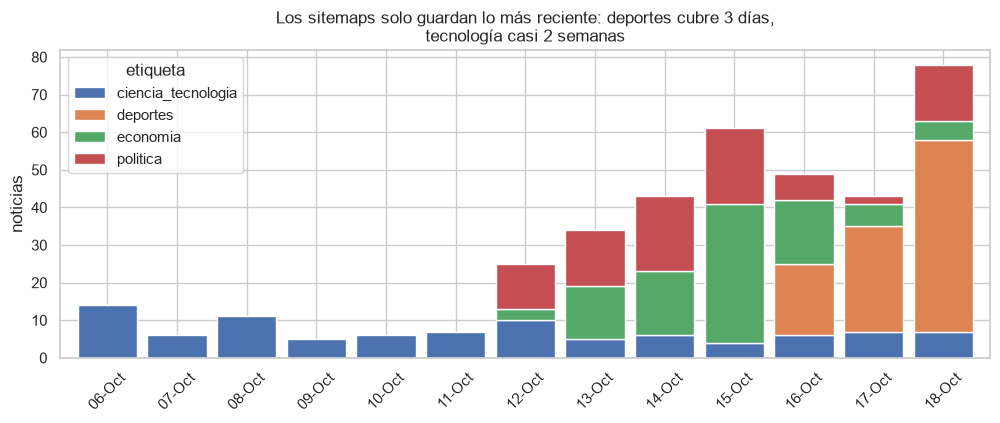

In [9]:
final["fecha_dt"] = pd.to_datetime(final.fecha)
por_dia = final.groupby(["fecha_dt", "etiqueta"]).size().unstack(fill_value=0)

ax = por_dia.plot(kind="bar", stacked=True, figsize=(12, 4), width=0.85)
ax.set_xticklabels([d.strftime("%d-%b") for d in por_dia.index], rotation=45)
ax.set_title("Los sitemaps solo guardan lo más reciente: deportes cubre 3 días,\ntecnología casi 2 semanas")
ax.set_xlabel(""); ax.set_ylabel("noticias")
plt.show()

Esto es una limitación importante y no un detalle: **cada categoría cubre una ventana de tiempo distinta**.
Las 98 notas de deportes son de solo 3 días (16 al 18 de octubre: un sitemap de 100 notas se llena rápido con
fútbol), política y economía abarcan una semana y tecnología llega hasta el 6 de octubre. Un modelo podría aprender «nombres propios de esta semana» en lugar de vocabulario
temático, y eso inflaría las métricas. Lo tengo presente al interpretar los resultados de la Parte 2.

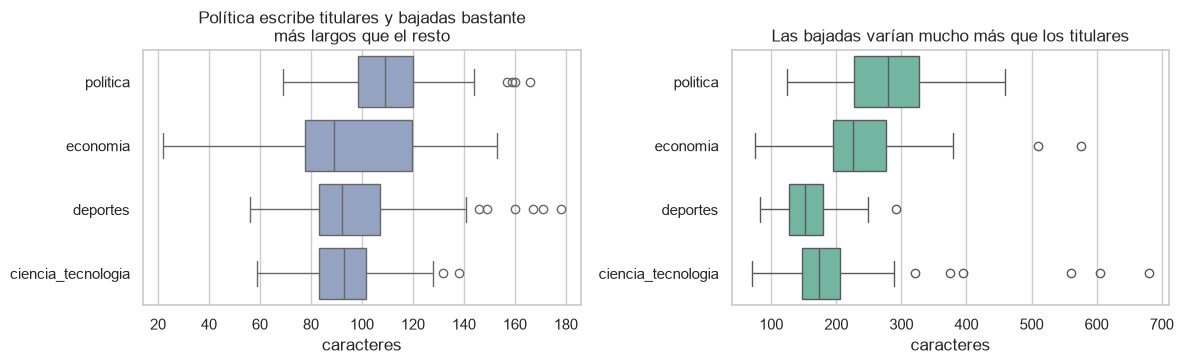

,n_car_titular,n_car_bajada
etiqueta,,
ciencia_tecnologia,93.0,173.0
deportes,92.0,152.5
economia,89.0,226.0
politica,109.0,279.0


In [10]:
final["n_car_titular"] = final.titular.str.len()
final["n_car_bajada"] = final.bajada.str.len()

fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.boxplot(data=final, y="etiqueta", x="n_car_titular", ax=ejes[0], color="#8DA0CB")
ejes[0].set_title("Política escribe titulares y bajadas bastante\nmás largos que el resto"); ejes[0].set_xlabel("caracteres"); ejes[0].set_ylabel("")
sns.boxplot(data=final, y="etiqueta", x="n_car_bajada", ax=ejes[1], color="#66C2A5")
ejes[1].set_title("Las bajadas varían mucho más que los titulares"); ejes[1].set_xlabel("caracteres"); ejes[1].set_ylabel("")
plt.tight_layout(); plt.show()

final.groupby("etiqueta")[["n_car_titular", "n_car_bajada"]].median()

Para sentir los datos antes de modelar, tres titulares al azar por categoría:

In [11]:
for et, g in final.groupby("etiqueta"):
    print(f"\n[{et}]")
    for _, f in g.sample(3, random_state=7).iterrows():
        print(f"  · ({f.seccion_original}) {f.titular}")


[ciencia_tecnologia]
  · (moviles) Ventas de ‘smartphones’ registran una caída del 20%, motivado por la crisis de memoria RAM
  · (ciberseguridad) Organización que gestiona Wikipedia denuncia actividad no autorizada de agentes de OpenAI
  · (actualidad) “Ace Combat 8: Wings of Theve” eleva la franquicia a alturas insospechadas | Reseña

[deportes]
  · (espana) VIDEO: ver goles del partido, Real Madrid 4-1 Sevilla por LaLiga 2026
  · (espana) Barcelona 5-2 Real Betis: ver resumen y goles ddel partido por LaLiga 2026
  · (futbol-mundial) Mourinho sorprende con mensaje sobre Vinícius: “Si estuviese en su lugar, probablemente no estaría aquí”

[economia]
  · (peru) El dólar abre a la baja en S/3,42 ante debilitamiento de la divisa estadounidense
  · (mercados) Wall Street cierra en rojo por dato de inflación en Estados Unidos y sector tecnológico
  · (peru) El Indecopi eliminó barreras burocráticas por S/ 429 millones en el 2025

[politica]
  · (politica) Ausencia de senadores de izquierd

## Qué queda para la Parte 2

- `datos/noticias.csv`: 7 columnas, URLs reales, etiqueta **provisional** por sección.
- `datos/raw/descartes.json`: lo que no entró y por qué.
- Sospechas ya anotadas: etiquetas con ruido (subsecciones como `actualidad` mezclan temas) y ventanas de
  tiempo distintas por categoría. En la Parte 2 las pongo a prueba con un LLM y con una auditoría manual.